##Bank Customer Churn Prediction
###Objective
Build a machine learning classification system that predicts whether a bank customer is likely to churn.
Target variable: churn
- 0 → Customer stayed
- 1 → Customer churned

### 1. Import Libraries

In [2]:
import warnings
warnings.filterwarnings("ignore")

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    roc_curve
)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

RANDOM_STATE = 42


### 2. Load the Dataset



In [3]:
import pandas as pd

# Load the bank customer churn prediction dataset
filepath = '/content/Bank Customer Churn Prediction.csv'
df = pd.read_csv(filepath)

# Display the first 5 rows
display(df.head())

,customer_id,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
0,15634602,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,15647311,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,15619304,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,15701354,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,15737888,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


### 3. Basic Dataset Inspection|


In [4]:
print("Column names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nDescriptive statistics:")
display(df.describe(include="all").T)


Column names:
['customer_id', 'credit_score', 'country', 'gender', 'age', 'tenure', 'balance', 'products_number', 'credit_card', 'active_member', 'estimated_salary', 'churn']

Data types:
customer_id           int64
credit_score          int64
country              object
gender               object
age                   int64
tenure                int64
balance             float64
products_number       int64
credit_card           int64
active_member         int64
estimated_salary    float64
churn                 int64
dtype: object

Missing values:
customer_id         0
credit_score        0
country             0
gender              0
age                 0
tenure              0
balance             0
products_number     0
credit_card         0
active_member       0
estimated_salary    0
churn               0
dtype: int64

Duplicate rows: 0

Descriptive statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customer_id,10000.0,NaN,NaN,NaN,15690940.5694,71936.186123,15565701.0,15628528.25,15690738.0,15753233.75,15815690.0
credit_score,10000.0,NaN,NaN,NaN,650.5288,96.653299,350.0,584.0,652.0,718.0,850.0
country,10000,3,France,5014,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,10000,2,Male,5457,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,10000.0,NaN,NaN,NaN,38.9218,10.487806,18.0,32.0,37.0,44.0,92.0
tenure,10000.0,NaN,NaN,NaN,5.0128,2.892174,0.0,3.0,5.0,7.0,10.0
balance,10000.0,NaN,NaN,NaN,76485.889288,62397.405202,0.0,0.0,97198.54,127644.24,250898.09
products_number,10000.0,NaN,NaN,NaN,1.5302,0.581654,1.0,1.0,1.0,2.0,4.0
credit_card,10000.0,NaN,NaN,NaN,0.7055,0.45584,0.0,0.0,1.0,1.0,1.0
active_member,10000.0,NaN,NaN,NaN,0.5151,0.499797,0.0,0.0,1.0,1.0,1.0


### 4. Data Cleaning

In [5]:
# Remove duplicate rows if any
df = df.drop_duplicates().reset_index(drop=True)

# Check target values
print("Target distribution:")
print(df["churn"].value_counts())

print("\nTarget percentage:")
print((df["churn"].value_counts(normalize=True) * 100).round(2))


Target distribution:
churn
0    7963
1    2037
Name: count, dtype: int64

Target percentage:
churn
0    79.63
1    20.37
Name: proportion, dtype: float64


### 5. Exploratory Data Analysis (EDA)
5.1 Churn Distribution

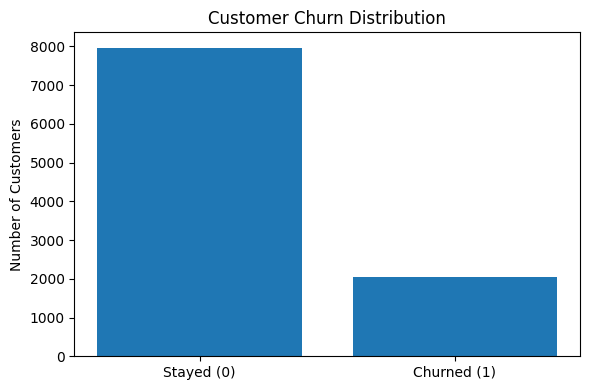

Overall churn rate: 20.37%


In [6]:
churn_counts = df["churn"].value_counts().sort_index()

plt.figure(figsize=(6, 4))
plt.bar(["Stayed (0)", "Churned (1)"], churn_counts.values)
plt.title("Customer Churn Distribution")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

churn_rate = df["churn"].mean() * 100
print(f"Overall churn rate: {churn_rate:.2f}%")


### 5.2 Churn by Country

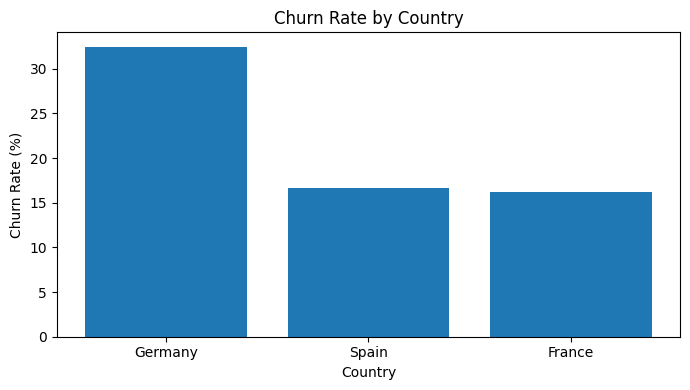

,Churn Rate (%)
country,
Germany,32.44
Spain,16.67
France,16.15


In [7]:
country_churn = df.groupby("country")["churn"].mean().sort_values(ascending=False) * 100

plt.figure(figsize=(7, 4))
plt.bar(country_churn.index, country_churn.values)
plt.title("Churn Rate by Country")
plt.ylabel("Churn Rate (%)")
plt.xlabel("Country")
plt.tight_layout()
plt.show()

display(country_churn.round(2).rename("Churn Rate (%)"))


### 5.3 Churn by Gender

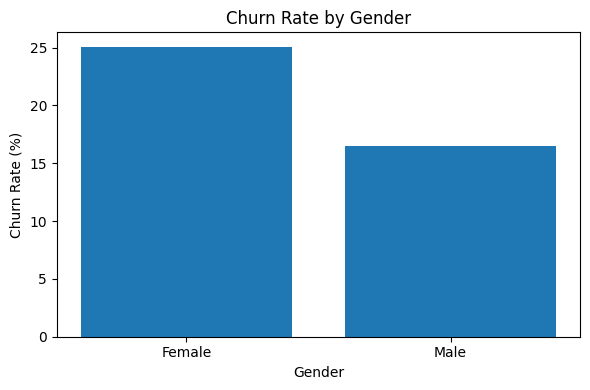

,Churn Rate (%)
gender,
Female,25.07
Male,16.46


In [8]:
gender_churn = df.groupby("gender")["churn"].mean().sort_values(ascending=False) * 100

plt.figure(figsize=(6, 4))
plt.bar(gender_churn.index, gender_churn.values)
plt.title("Churn Rate by Gender")
plt.ylabel("Churn Rate (%)")
plt.xlabel("Gender")
plt.tight_layout()
plt.show()

display(gender_churn.round(2).rename("Churn Rate (%)"))


### 5.4 Churn by Active Membership

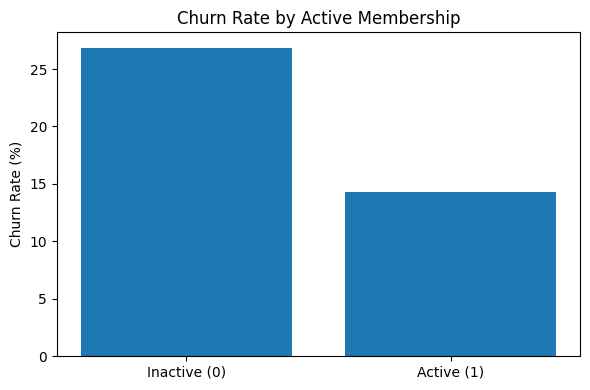

,Churn Rate (%)
active_member,
0,26.85
1,14.27


In [9]:
active_churn = df.groupby("active_member")["churn"].mean() * 100

plt.figure(figsize=(6, 4))
plt.bar(["Inactive (0)", "Active (1)"], active_churn.values)
plt.title("Churn Rate by Active Membership")
plt.ylabel("Churn Rate (%)")
plt.tight_layout()
plt.show()

display(active_churn.round(2).rename("Churn Rate (%)"))


### 5.5 Churn by Number of Products

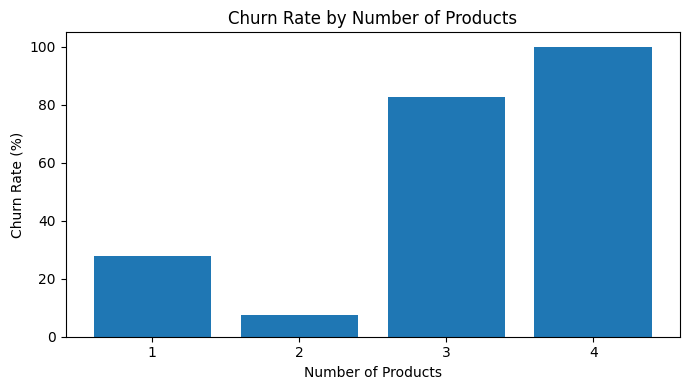

,Churn Rate (%)
products_number,
1,27.71
2,7.58
3,82.71
4,100.00


In [10]:
product_churn = df.groupby("products_number")["churn"].mean() * 100

plt.figure(figsize=(7, 4))
plt.bar(product_churn.index.astype(str), product_churn.values)
plt.title("Churn Rate by Number of Products")
plt.xlabel("Number of Products")
plt.ylabel("Churn Rate (%)")
plt.tight_layout()
plt.show()

display(product_churn.round(2).rename("Churn Rate (%)"))


### 5.6 Age Distribution by Churn

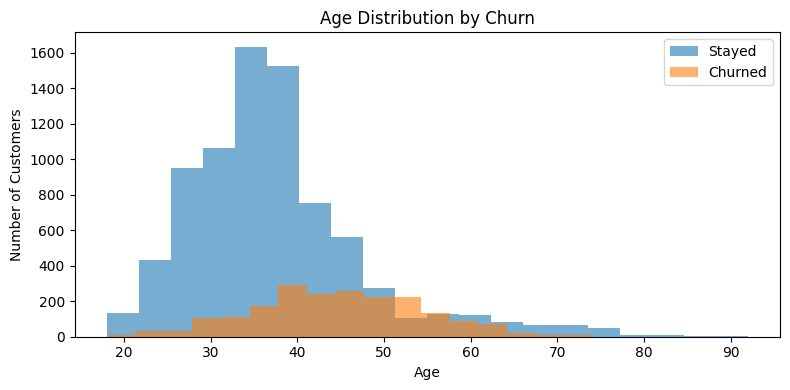

Average age of customers who stayed: 37.41
Average age of customers who churned: 44.84


In [11]:
stayed_age = df.loc[df["churn"] == 0, "age"]
churned_age = df.loc[df["churn"] == 1, "age"]

plt.figure(figsize=(8, 4))
plt.hist(stayed_age, bins=20, alpha=0.6, label="Stayed")
plt.hist(churned_age, bins=20, alpha=0.6, label="Churned")
plt.title("Age Distribution by Churn")
plt.xlabel("Age")
plt.ylabel("Number of Customers")
plt.legend()
plt.tight_layout()
plt.show()

print("Average age of customers who stayed:", round(stayed_age.mean(), 2))
print("Average age of customers who churned:", round(churned_age.mean(), 2))


### 5.7 Numerical Feature Comparison

In [12]:
numerical_features = [
    "credit_score",
    "age",
    "tenure",
    "balance",
    "products_number",
    "estimated_salary"
]

mean_by_churn = df.groupby("churn")[numerical_features].mean().T
mean_by_churn.columns = ["Stayed (0)", "Churned (1)"]

display(mean_by_churn.round(2))


,Stayed (0),Churned (1)
credit_score,651.85,645.35
age,37.41,44.84
tenure,5.03,4.93
balance,72745.30,91108.54
products_number,1.54,1.48
estimated_salary,99738.39,101465.68


### 6. Define Features and Target
removed customer_id because it is only a unique identifier and does not represent customer behavior.

In [13]:
X = df.drop(columns=["churn", "customer_id"])
y = df["churn"]

print("Features:")
print(X.columns.tolist())

print("\nTarget:")
print("churn")


Features:
['credit_score', 'country', 'gender', 'age', 'tenure', 'balance', 'products_number', 'credit_card', 'active_member', 'estimated_salary']

Target:
churn


### 7. Train-Test Split
A stratified split preserves the churn/non-churn ratio in both training and testing data.

In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE
)

print("Training set:", X_train.shape)
print("Testing set :", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).round(3))


Training set: (8000, 10)
Testing set : (2000, 10)

Training target distribution:
churn
0    0.796
1    0.204
Name: proportion, dtype: float64

Testing target distribution:
churn
0    0.796
1    0.204
Name: proportion, dtype: float64


### 8. Preprocessing
Categorical columns are one-hot encoded. Numerical columns are standardized.
Using a Pipeline and ColumnTransformer ensures preprocessing is learned only from the training data and avoids data leakage.

In [15]:
categorical_features = X.select_dtypes(include=["object", "category"]).columns.tolist()
numerical_features = X.select_dtypes(exclude=["object", "category"]).columns.tolist()

print("Categorical features:", categorical_features)
print("Numerical features :", numerical_features)

numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)


Categorical features: ['country', 'gender']
Numerical features : ['credit_score', 'age', 'tenure', 'balance', 'products_number', 'credit_card', 'active_member', 'estimated_salary']


### 9. Train Baseline Classification Models
We compare several models:
- Logistic Regression
- Decision Tree
- Random Forest
- Gradient Boosting
- XGBoost

In [17]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=6,
        min_samples_split=10,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        max_depth=10,
        min_samples_split=5,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        random_state=RANDOM_STATE
    )
}

# XGBoost is optional
try:
    from xgboost import XGBClassifier

    scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

    models["XGBoost"] = XGBClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=4,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=scale_pos_weight,
        eval_metric="logloss",
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
    print("XGBoost is available and has been added.")
except ImportError:
    print("XGBoost is not installed. Run: pip install xgboost")


XGBoost is available and has been added.


### 10. Train and Evaluate Models

In [18]:
def evaluate_model(name, model, X_train, X_test, y_train, y_test):
    pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("model", model)
        ]
    )

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    metrics = {
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    }

    print(f"\n{'=' * 60}")
    print(name)
    print("=" * 60)
    print(classification_report(y_test, y_pred, digits=4))

    return pipeline, metrics, y_pred, y_prob


trained_models = {}
results = []

for name, model in models.items():
    pipeline, metrics, y_pred, y_prob = evaluate_model(
        name, model, X_train, X_test, y_train, y_test
    )
    trained_models[name] = pipeline
    results.append(metrics)

results_df = pd.DataFrame(results).sort_values("ROC-AUC", ascending=False).reset_index(drop=True)

display(results_df.round(4))



Logistic Regression
              precision    recall  f1-score   support

           0     0.9035    0.7169    0.7994      1593
           1     0.3872    0.7002    0.4987       407

    accuracy                         0.7135      2000
   macro avg     0.6454    0.7086    0.6491      2000
weighted avg     0.7984    0.7135    0.7382      2000


Decision Tree
              precision    recall  f1-score   support

           0     0.9269    0.7558    0.8326      1593
           1     0.4451    0.7666    0.5632       407

    accuracy                         0.7580      2000
   macro avg     0.6860    0.7612    0.6979      2000
weighted avg     0.8288    0.7580    0.7778      2000


Random Forest
              precision    recall  f1-score   support

           0     0.9120    0.8908    0.9012      1593
           1     0.6081    0.6634    0.6345       407

    accuracy                         0.8445      2000
   macro avg     0.7600    0.7771    0.7679      2000
weighted avg     0.8501

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Gradient Boosting,0.8705,0.7937,0.4914,0.6070,0.8697
1,XGBoost,0.8070,0.5179,0.7469,0.6117,0.8657
2,Random Forest,0.8445,0.6081,0.6634,0.6345,0.8621
3,Decision Tree,0.7580,0.4451,0.7666,0.5632,0.8324
4,Logistic Regression,0.7135,0.3872,0.7002,0.4987,0.7772


### 11. Visualize Model Comparison

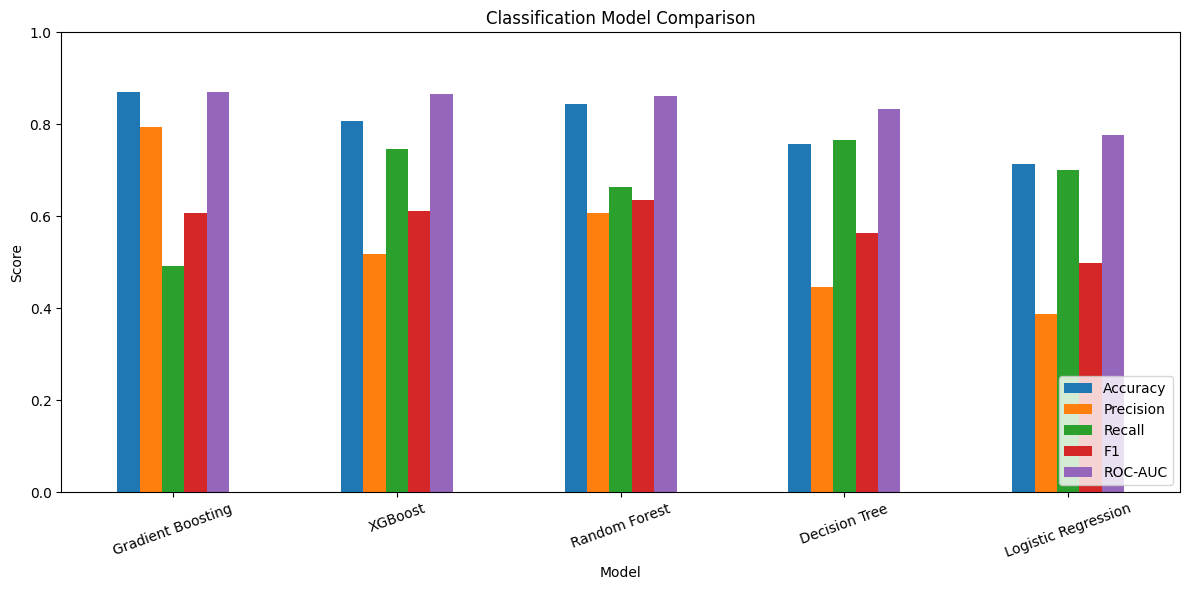

In [19]:
metric_columns = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]

ax = results_df.set_index("Model")[metric_columns].plot(
    kind="bar",
    figsize=(12, 6)
)

ax.set_title("Classification Model Comparison")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
plt.xticks(rotation=20)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


### 12. ROC Curves

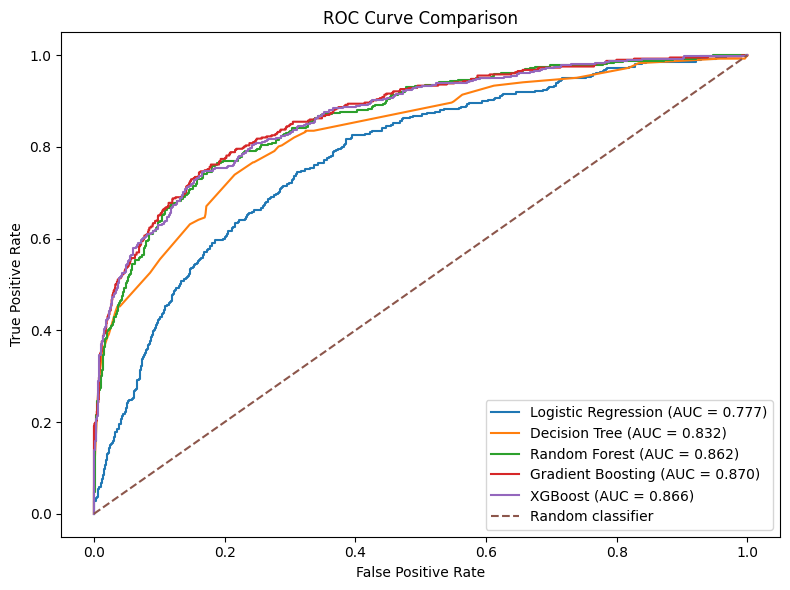

In [20]:
plt.figure(figsize=(8, 6))

for name, pipeline in trained_models.items():
    y_prob = pipeline.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc = roc_auc_score(y_test, y_prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--", label="Random classifier")
plt.title("ROC Curve Comparison")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.tight_layout()
plt.show()


In [21]:
X = df.drop("churn", axis=1)
y = df["churn"]

# Remove customer ID
X = X.drop("customer_id", axis=1)

# Encode categorical columns
X = pd.get_dummies(X, columns=["country", "gender"], drop_first=True)

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

### 13. Hyperparameter Tuning
Fine tunning Random Forest

In [22]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

rf = RandomForestClassifier(
    random_state=42,
    class_weight="balanced"
)

rf_param_grid = {
    "n_estimators": [200, 300],
    "max_depth": [10, 20, None],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2],
    "max_features": ["sqrt", "log2"]
}

rf_grid = GridSearchCV(
    estimator=rf,
    param_grid=rf_param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1,
    verbose=1
)

rf_grid.fit(X_train, y_train)

print("Best Parameters:")
print(rf_grid.best_params_)

print("\nBest CV F1 Score:")
print(rf_grid.best_score_)

Fitting 5 folds for each of 48 candidates, totalling 240 fits
Best Parameters:
{'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 300}

Best CV F1 Score:
0.6284594119398864


### 14. Evaluate the Tuned Model

In [24]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# Best tuned model
best_rf = rf_grid.best_estimator_

# Predictions
y_pred_tuned = best_rf.predict(X_test)
y_prob_tuned = best_rf.predict_proba(X_test)[:, 1]

print("=" * 60)
print("TUNED RANDOM FOREST RESULTS")
print("=" * 60)

print("Accuracy :", accuracy_score(y_test, y_pred_tuned))
print("Precision:", precision_score(y_test, y_pred_tuned))
print("Recall   :", recall_score(y_test, y_pred_tuned))
print("F1 Score :", f1_score(y_test, y_pred_tuned))
print("ROC-AUC  :", roc_auc_score(y_test, y_prob_tuned))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_tuned))

TUNED RANDOM FOREST RESULTS
Accuracy : 0.837
Precision: 0.5914221218961625
Recall   : 0.6437346437346437
F1 Score : 0.6164705882352941
ROC-AUC  : 0.8627333034112694

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.89      0.90      1593
           1       0.59      0.64      0.62       407

    accuracy                           0.84      2000
   macro avg       0.75      0.77      0.76      2000
weighted avg       0.84      0.84      0.84      2000



### 15. Confusion Matrix

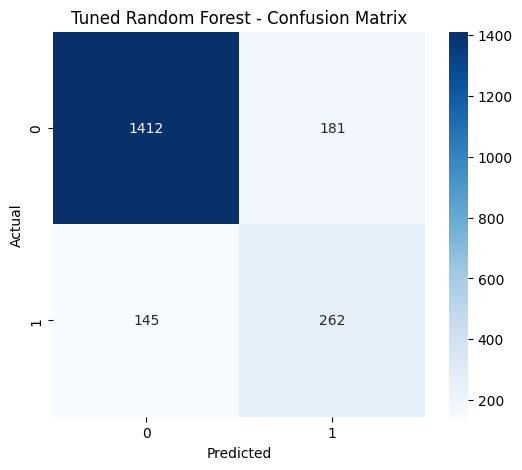

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 5))

sns.heatmap(
    confusion_matrix(y_test, y_pred_tuned),
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Tuned Random Forest - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

### 16. Feature Importance
Feature Importance using the Random Forest, not the tuned one.

In [35]:
# Retrieve the original trained Random Forest pipeline
original_rf_pipeline = trained_models["Random Forest"]

# Extract the feature names from the preprocessor step
feature_names = original_rf_pipeline.named_steps["preprocessor"].get_feature_names_out()

# Extract the feature importances from the classifier step
importances = original_rf_pipeline.named_steps["model"].feature_importances_

# Create a structured DataFrame for display
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values("Importance", ascending=False)

display(feature_importance)

,Feature,Importance
1,num__age,0.315733
4,num__products_number,0.196229
3,num__balance,0.116409
7,num__estimated_salary,0.082326
0,num__credit_score,0.080893
6,num__active_member,0.053292
2,num__tenure,0.048088
9,cat__country_Germany,0.043242
8,cat__country_France,0.014277
12,cat__gender_Male,0.013845


### 18. Example Customer Prediction

In [59]:
# Use the original Random Forest pipeline
final_model = trained_models["Random Forest"]

# Select one actual customer from the original DataFrame before pd.get_dummies was applied
# This matches the schema with raw categorical values like 'Germany' and 'Male'
sample_customer_id = y_test.index[18]
customer_raw = df.loc[[sample_customer_id]].drop(columns=["churn", "customer_id"])

# Get the actual churn value
actual_churn = y_test.iloc[0]

# Make prediction
prediction = final_model.predict(customer_raw)[0]

# Get churn probability
churn_probability = final_model.predict_proba(customer_raw)[0][1]

print("=" * 60)
print("CUSTOMER CHURN PREDICTION")
print("=" * 60)

print("\nCustomer Details:")
display(customer_raw)

print("\nActual Churn     :", actual_churn)
print("Predicted Churn  :", prediction)
print("Churn Probability:", round(churn_probability * 100, 2), "%")

if prediction == 1:
    print("\nPrediction: Customer is likely to CHURN")
else:
    print("\nPrediction: Customer is likely to STAY")

CUSTOMER CHURN PREDICTION

Customer Details:


,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary
2350,617,Germany,Female,58,3,119024.75,2,1,0,35199.24



Actual Churn     : 0
Predicted Churn  : 1
Churn Probability: 77.01 %

Prediction: Customer is likely to CHURN


### 19. Save the Final Model
The trained pipeline includes preprocessing and the model, so a new application can use the saved file directly.

In [61]:
import joblib

# Save the original baseline Random Forest pipeline as selected
final_pipeline = trained_models["Random Forest"]

MODEL_PATH = "bank_customer_churn_model.pkl"
joblib.dump(final_pipeline, MODEL_PATH)

print(f"Final baseline Random Forest model pipeline saved successfully to: {MODEL_PATH}")

Final baseline Random Forest model pipeline saved successfully to: bank_customer_churn_model.pkl


### Business Interpretation
The model can help a bank identify customers at higher risk of leaving and prioritize retention actions such as targeted offers, relationship-manager outreach, or personalized service.